# Semivariogram

By calculating semivariogram functions for both our kiln locations and the control locations, we can quantify how spatially autocorrelated pixels are, i.e. the correlation between two pixels as a function of distance between these pixels.  

***
## Motivation
This serves two things:
1. Ring intervals: if the pixels within our ring interval are heavily correlated, any measurements calculated form the pixel values will be biased. The semivariogram does not fix this problem, it simply gives us a distance up to which pixels are expected to be correlated, i.e. if our ring intervals is in that range, we need to take this into consideration when discussing our results.
2. By comparing the semivariogram functions of the control points and the actual charcoal mounds, we can see whether there is a difference in spatial autocorrelation between areas around a charcoal mound and generic areas.

## Method
1. **One window per point**. Around each charcoal mound (or control point), the code reads a square window from the raster: `half_width` = 50m in each direction, so 100m $\times$ 100m. At 1m pixels that's 100 $\times$ 100 pixels
2. **Optional detrending**. If `detrend=True`, it fits a flat plane (height = a + b $\times$ row + c $\times$ column) to each window by least squares and subtracts it. That removes straight til, e.g. from slope, so the curve isn't dominated by terrain. It cannot remove anything curved like a bump or dip at the centre.
3. **Form pixel pairs at each distance**. Within the window, every pixel is paired with the pixel k steps away in four directions:
    - east (distance $k \times$ pixel size)
    - north (same)
    - north-east and north-west diagonals (distance $k \times \sqrt{2} \times$ pixel size)
It does this for every $k$ up to `max_lag` = 40m. Technically it shifts the whole array by (rows, columns) and lines up the two copies, so all pairs for one shift are computed at once. Only four firections are needed because the opposite ones (west, south, ...) give the same pairs again.
4. **Square differences**. For each pair it takes $(z_1-z_2)^2$. Pairs where either pixel is missing (NaN) are dropped.
5. **Bin by distance**. Each pair's distance is rounded to the nearest pixel size, so diagonal pairs (e.g. 1.41m) land in the same bins as straight ones (1m). For each bin it keeps two running totals: the sum of squared differences and the number of pairs.
6. **Pool across all windows**. Steps 3-5 are repeated for every point, adding to the same totals. So it's one curve for all kilns together, with every pair counting equally, not an average of per-kiln curves.
7. **Compute semivariance**. For each distance bin: $\gamma(h) = \frac{1}{2} \times \frac{\text{sum of squared differences}}{\text{number of pairs}}$. The $\frac{1}{2}$ is the "semi": it makes $\gamma$ approach the variance of the heights at large distances, so the sill is roughly the variance.
8. **Same thing for controls**. Running it with `{"gpkg": "controls_2056.gpkg"}` repeats exactly this with windows around the control points, which is why the curves are directly comparable as long as all other settings are identical.

## Calculating Semivariogram
We will use the defined functions from `semivariogram_function.py`.

In [1]:
%load_ext autoreload
%autoreload 2

import matplotlib.pyplot as plt
import numpy as np

from semivariogram_function import (kiln_semivariogram, plot_semivariogram,
                                    site_sums, bootstrap_semivariogram,
                                    bootstrap_difference, plot_band, _subset)
from helpers import save_fig

80 windows of 100 x 100 m, pixel size 1.0 m
189 windows of 100 x 100 m, pixel size 1.0 m


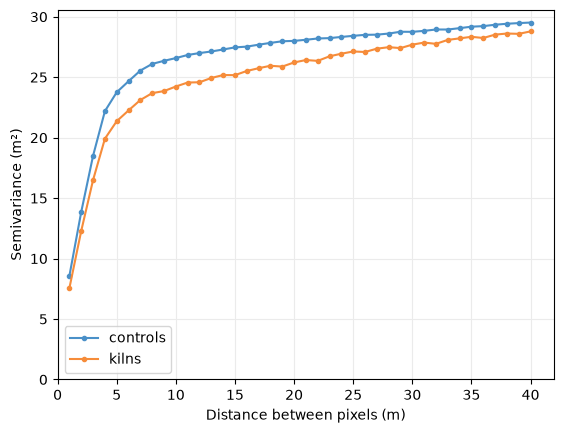

In [ ]:
sv_kiln = kiln_semivariogram({"tif": "merged_dem.tif", "detrend": False})
sv_ctrl = kiln_semivariogram({"tif": "merged_dem.tif", "detrend": False,
                              "gpkg": "controls_2056.gpkg"})
fig, ax = plt.subplots()
plot_semivariogram(sv_ctrl, ax=ax, label="controls", color="#4A90C8")
plot_semivariogram(sv_kiln, ax=ax, label="kilns", color="#F68C3A")
ax.legend()

This comparison, however, is flawed. The orange curve above is calculated from all charcoal mounds. While this correctly represents the semivariogram of the entire population, we cannot compare it directly to the control point's semivariogram. This is because not all charcoal mounds have control points. This was done deliberately since some charcoal mounds lie outside forested areas (either above the tree line, in the lake or other reasons) and thus finding a representative control point is impossible to do without bias. Hence in the following plots we will start to work with the narrowed down selection of charcoal mounds that received control points (66 instead of 80).

## Bootstrap 95% Interval
To get a reliable sense of how much these two curves differ, we can bootstrap the semivariogram curves to get a 95% confidence interval around each of the curves. This is how it's done
1. We draw 80 charcoal mounds with replacement from the original 80 charcoal mounds. For control points, we draw charcoal mound groups and take each group's controls along (this is done because each charcoal mound has up to 3 corresponding control points).
2. The we compute the semivariogram from only those windows as described above.
3. This is repeated $n$ times
4. At each distance, we take the 2.5% and 97% values of all repeats to become the band.  

Because we do not want to rerun the semivariogram calculations $n$ times, we calculate the pairwise comparisons once and then use these results with the drawn points.

66 kilns with controls used


[PosixPath('/Users/paulghisletti/Desktop/GEO715/GEO-715-Project/new testfolder/figures/semivariogram_bootstrap.png'),
 PosixPath('/Users/paulghisletti/Desktop/GEO715/GEO-715-Project/new testfolder/figures/semivariogram_bootstrap.pdf')]

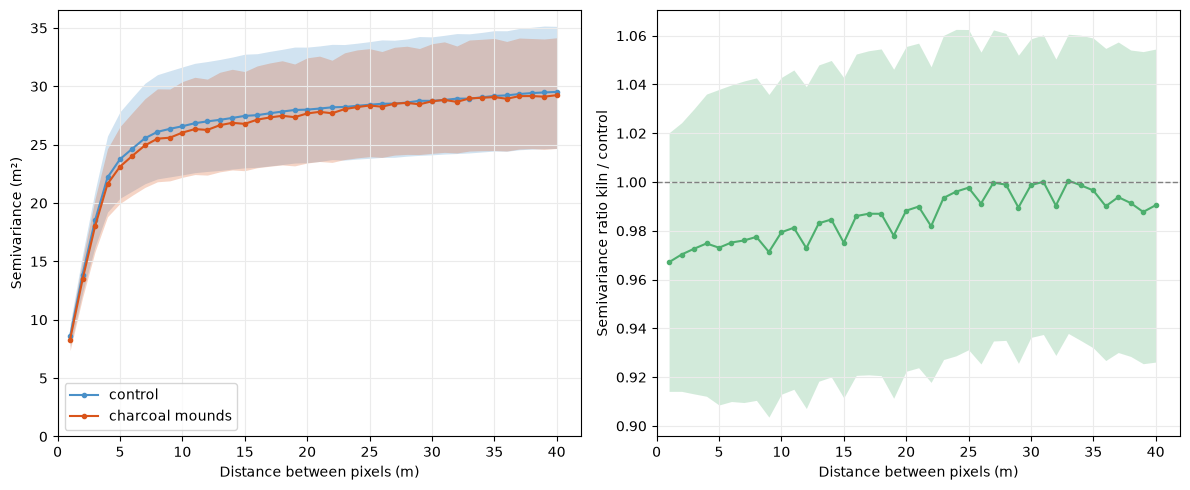

In [12]:
settings = {"tif": "merged_dem.tif", "detrend": False}

kiln = site_sums({**settings, "gpkg": "kohlmeiler_2056.gpkg"}, group_column="ID_PAROLINI")
ctrl = site_sums({**settings, "gpkg": "controls_2056.gpkg"}, group_column="kiln_id")

ids = np.intersect1d(np.unique(kiln["groups"]), np.unique(ctrl["groups"]))
kiln_m = {**kiln, **_subset(kiln, ids)}
ctrl_m = {**ctrl, **_subset(ctrl, ids)}

bs_kiln = bootstrap_semivariogram(kiln_m)
bs_ctrl = bootstrap_semivariogram(ctrl_m)
ratio = bootstrap_difference(kiln_m, ctrl_m)

fig, ax = plt.subplots(1,2, figsize=(12,5))
plot_band(bs_ctrl, ax=ax[0], label="control", color="#4A90C8")
plot_band(bs_kiln, ax=ax[0], label="charcoal mounds", color="#D9541A")
ax[0].legend()
plot_band(ratio, ax=ax[1], color="#4DAF6E")
plt.tight_layout()

save_fig("semivariogram_bootstrap", fig=fig)

## Interpretation
### 1. Shape of the semivariograms
- Semivariance rises steeply up to about 5-8m, then it flattens but keeps creeping up without reaching a clear sill by 40m.
- That means pixels closer than roughly 5-8m are strongly similar, and beyond that similarity drops off. This scale fits the width of individual tree crowns.
- The slow contiunued rise points to some larger-scale variation in vegetation structure, such as gaps, groups of trees or changes in stand height.
### 2. Kilns vs controls
- The charcoal mound curve lies slightly below the control curve up to about 25m. Then the two practically coincide.
- So the surroundings of charcoal mounds are slightly smoother at short distances. This indicates more uniform vegetation growth. This could be more even regrowth on former charcoal mound sites (not proven).
### 3. Size of differences
- The ratio is about 0.97 at 1m, so charcoal mound semivariance is roughly 3% lower.
- The difference rises to about 1.0 from around 25m onwards, so the difference is a short-range effect disappearing at larger distances.
- Again, that's consistent with something local around the kiln, such as the levelled platform or a more uniform regrowth patch, but it's a small effect.
### 4. Zigzag pattern
- The alternating peaks , for example at 9, 12, 15, 19 and 22m, are most likely a pixel-grid artefact. Some distances are dominated by diagonal pairs and others by axis-aligned ones, with different pair counts.
- These wiggles should therefore not be interpreted, rather the entire structure should be assessed.
### 5. Significance
- The 95% band of the ratio spans about 0.91 to 1.06 and contains 1 at every position. The two bands on the left overlap almost completely for all distances.
- So charcoal mounds and controls cannot be distinguished statistically at a 5% level.
- The ratio staying below 1 at every lag up to 25m does not add up to strong evidence either. Neighbouring lags share most of their pixels and are strongly correlated, so this a singular weak signal, not one signal for each distance.
